In [ ]:
import tensorflow as tf
import os
train_dir = "10_food_classes_all_data/train/"
test_dir = "10_food_classes_all_data/test/"

# How many images are we working with now?
for dirpath, dirnames, filenames in os.walk("C:\\Interview Process\\python_tf\\TransferLearning_fineTuneing\\all data\\10_food_classes_all_data"):
  print(f"There are {len(dirnames)} directories and {len(filenames)} images in '{dirpath}'.")

There are 2 directories and 0 images in 'C:\Interview Process\python_tf\TransferLearning_fineTuneing\all data\10_food_classes_all_data'.
There are 10 directories and 0 images in 'C:\Interview Process\python_tf\TransferLearning_fineTuneing\all data\10_food_classes_all_data\test'.
There are 0 directories and 250 images in 'C:\Interview Process\python_tf\TransferLearning_fineTuneing\all data\10_food_classes_all_data\test\chicken_curry'.
There are 0 directories and 250 images in 'C:\Interview Process\python_tf\TransferLearning_fineTuneing\all data\10_food_classes_all_data\test\chicken_wings'.
There are 0 directories and 250 images in 'C:\Interview Process\python_tf\TransferLearning_fineTuneing\all data\10_food_classes_all_data\test\fried_rice'.
There are 0 directories and 250 images in 'C:\Interview Process\python_tf\TransferLearning_fineTuneing\all data\10_food_classes_all_data\test\grilled_salmon'.
There are 0 directories and 250 images in 'C:\Interview Process\python_tf\TransferLearning

In [ ]:
IMG_SIZE = (256, 256)
train_data_10_classes_full = tf.keras.preprocessing.image_dataset_from_directory(train_dir,
                                                                                 label_mode="categorical",
                                                                                 image_size=IMG_SIZE)

# Note: this is the same test dataset we've been using for the previous modelling experiments
test_data = tf.keras.preprocessing.image_dataset_from_directory(test_dir,
                                                                label_mode="categorical",
                                                                image_size=IMG_SIZE)

Found 7500 files belonging to 10 classes.
Found 2500 files belonging to 10 classes.


In [ ]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

data_augmentation = keras.Sequential([
    keras.Input(shape=(256, 256, 3)),
    layers.RandomFlip("horizontal"), 
    layers.RandomRotation(0.2),
    layers.RandomZoom(0.2),
    layers.RandomHeight(0.2),
    layers.RandomWidth(0.2),
    layers.Rescaling(1./255)
], name="data_augmentation")

In [ ]:
input_shape = (256, 256, 3)
base_model = tf.keras.applications.EfficientNetB0(
    include_top=False,
    input_shape=input_shape,
)
base_model.trainable = False
inputs = tf.keras.layers.Input(shape=input_shape, name="input_layer")

x= data_augmentation(inputs)

x= base_model(x, training=False)

x = layers.GlobalAveragePooling2D(name="global_average_pooling_layer")(x)

outputs = layers.Dense(len(train_data_10_classes_full.class_names), activation="softmax", name="output_layer")(x)

model_2 = tf.keras.Model(inputs, outputs)

In [ ]:
checkpoint_path = 'C:\\Interview Process\\python_tf\\TransferLearning_fineTuneing\\TransferLearning_fineTuneing\\checkpoints\\cp.weights.h5'
# Load previously checkpointed weights
model_2.load_weights(checkpoint_path)

In [ ]:
checkpoint_path = 'C:\\Interview Process\\python_tf\\TransferLearning_fineTuneing\\TransferLearning_fineTuneing\\checkpoints\\cp.weights.h5'
# Load previously checkpointed weights
model_2.load_weights(checkpoint_path)

In [ ]:
model_2.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 256, 256, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, None, None, 3)  │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, None, None,     │     4,049,571 │
│                                 │ 1280)                  │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling_layer    │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output_layer (Dense)            │ (None, 10)             │        12,810 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,062,381 (15.50 MB)

 Trainable params: 12,810 (50.04 KB)

 Non-trainable params: 4,049,571 (15.45 MB)

In [ ]:
print(len(model_2.trainable_variables))

2


In [ ]:
# Unfreeze the top 10 layers in model_2's base_model
model_2_base_model = model_2.layers[2]
model_2_base_model.trainable = True

# Freeze all layers except for the last 10
for layer in model_2_base_model.layers[:-10]:
  layer.trainable = False

In [ ]:
# Recompile the model (always recompile after any adjustments to a model)
model_2.compile(loss="categorical_crossentropy",
                optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001), # lr is 10x lower than before for fine-tuning
                metrics=["accuracy"])

In [ ]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

data_augmentation = keras.Sequential([
    keras.Input(shape=(256, 256, 3)),
    layers.RandomFlip("horizontal"), 
    layers.RandomRotation(0.2),
    layers.RandomZoom(0.2),
    layers.RandomHeight(0.2),
    layers.RandomWidth(0.2),
    # layers.Rescaling(1./255)
], name="data_augmentation")

In [ ]:
input_shape = (256, 256, 3)
base_model = tf.keras.applications.EfficientNetB0(
    include_top=False,
    input_shape=input_shape,
)
base_model.trainable = False
inputs = tf.keras.layers.Input(shape=input_shape, name="input_layer")

x= data_augmentation(inputs)

x= base_model(x, training=False)

x = layers.GlobalAveragePooling2D(name="global_average_pooling_layer")(x)

outputs = layers.Dense(len(train_data_10_classes_full.class_names), activation="softmax", name="output_layer")(x)

model_2 = tf.keras.Model(inputs, outputs)

In [ ]:
checkpoint_path = 'C:\\Interview Process\\python_tf\\TransferLearning_fineTuneing\\TransferLearning_fineTuneing\\checkpoints\\cp.weights.h5'
# Load previously checkpointed weights
model_2.load_weights(checkpoint_path)

In [ ]:
# Unfreeze the top 10 layers in model_2's base_model
model_2_base_model = model_2.layers[2]
model_2_base_model.trainable = True

# Freeze all layers except for the last 10
for layer in model_2_base_model.layers[:-10]:
  layer.trainable = False

In [ ]:
# Unfreeze the top 10 layers in model_2's base_model
model_2_base_model = model_2.layers[2]
model_2_base_model.trainable = True

# Freeze all layers except for the last 10
for layer in model_2_base_model.layers[:-10]:
  layer.trainable = False

In [ ]:
# Recompile the model (always recompile after any adjustments to a model)
model_2.compile(loss="categorical_crossentropy",
                optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001), # lr is 10x lower than before for fine-tuning
                metrics=["accuracy"])

In [ ]:
# Continue to train and fine-tune the model to our data
fine_tune_epochs = 10

history_fine_10_classes_full = model_2.fit(train_data_10_classes_full,
                                           epochs=fine_tune_epochs,
                                           validation_data=test_data,
                                           validation_steps=int(0.25 * len(test_data)))

Epoch 1/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 274s 1s/step - accuracy: 0.7837 - loss: 0.7411 - val_accuracy: 0.8898 - val_loss: 0.3635
Epoch 2/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 313s 1s/step - accuracy: 0.8241 - loss: 0.5591 - val_accuracy: 0.8964 - val_loss: 0.3158
Epoch 3/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 274s 1s/step - accuracy: 0.8536 - loss: 0.4814 - val_accuracy: 0.8997 - val_loss: 0.2890
Epoch 4/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 291s 1s/step - accuracy: 0.8639 - loss: 0.4444 - val_accuracy: 0.9046 - val_loss: 0.2868
Epoch 5/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 318s 1s/step - accuracy: 0.8695 - loss: 0.4132 - val_accuracy: 0.9227 - val_loss: 0.2618
Epoch 6/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 317s 1s/step - accuracy: 0.8876 - loss: 0.3751 - val_accuracy: 0.9260 - val_loss: 0.2288
Epoch 7/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 294s 1s/step - accuracy: 0.8881 - loss: 0.3595 - val_accuracy: 0.9227 - val_loss: 0.2558
Epoch 8/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 285s 1s/step - accuracy: 0.8905 - loss: 0.3414 - val_accu

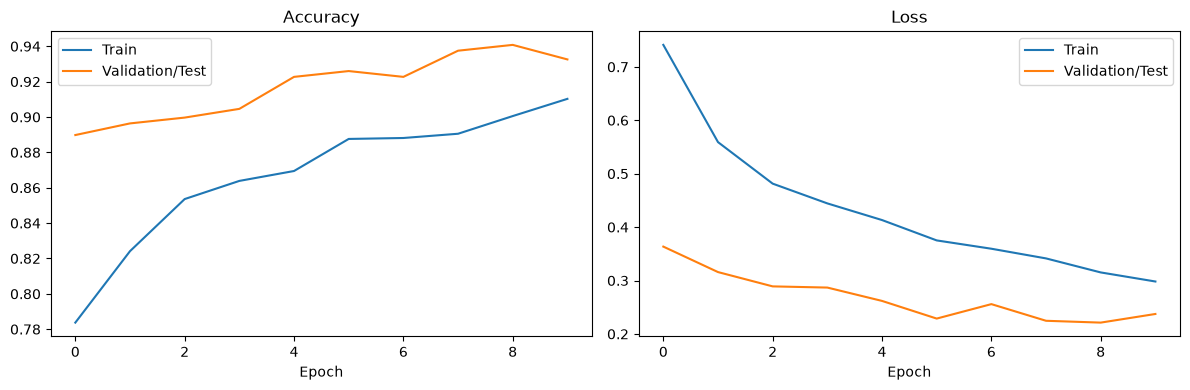

In [ ]:
import matplotlib.pyplot as plt

history = history_fine_10_classes_full.history
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history["accuracy"], label="Train")
plt.plot(history["val_accuracy"], label="Validation/Test")
plt.title("Accuracy")
plt.xlabel("Epoch")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history["loss"], label="Train")
plt.plot(history["val_loss"], label="Validation/Test")
plt.title("Loss")
plt.xlabel("Epoch")
plt.legend()

plt.tight_layout()
plt.show()

In [ ]:
checkpoint_path = 'C:\\Interview Process\\python_tf\\TransferLearning_fineTuneing\\TransferLearning_fineTuneing\\checkpoints\\cp.weights.h5'
fine_tuned_checkpoint_path = os.path.join(
    os.path.dirname(checkpoint_path), "fine_tuned.weights.h5"
)
model_2.save_weights(fine_tuned_checkpoint_path)

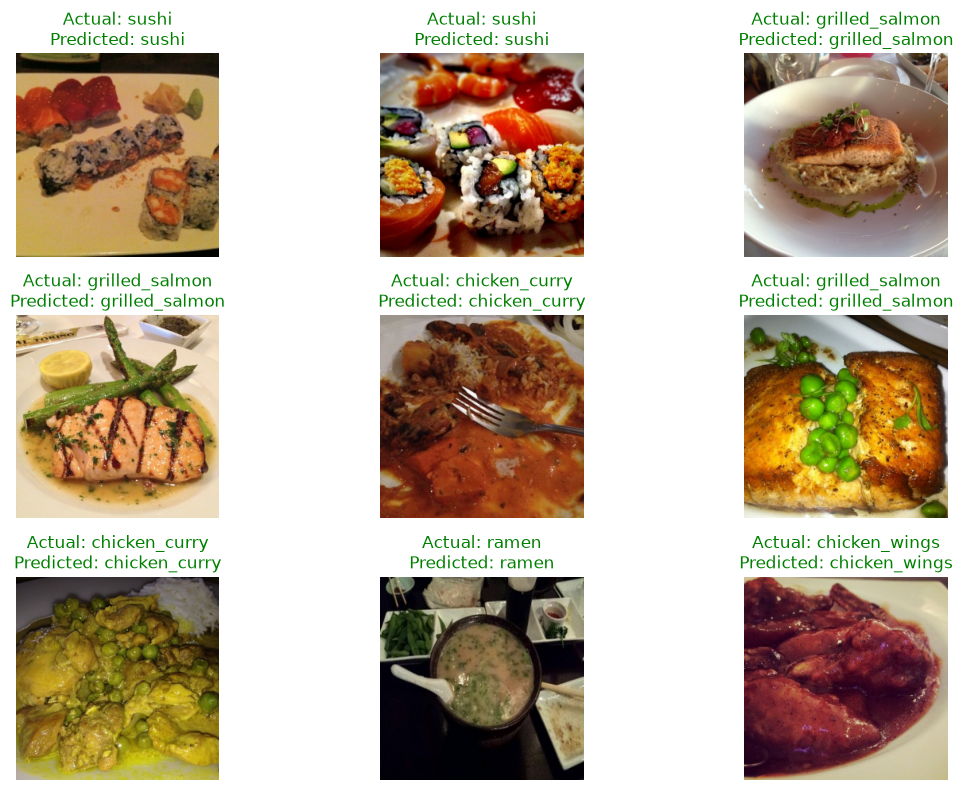

In [ ]:
images, labels = next(iter(test_data))
predictions = model_2.predict(images, verbose=0)

plt.figure(figsize=(12, 8))
for i in range(min(9, len(images))):
    actual = train_data_10_classes_full.class_names[tf.argmax(labels[i]).numpy()]
    predicted = train_data_10_classes_full.class_names[tf.argmax(predictions[i]).numpy()]
    plt.subplot(3, 3, i + 1)
    plt.imshow(images[i].numpy().astype("uint8"))
    plt.title(f"Actual: {actual}\nPredicted: {predicted}",
              color="green" if actual == predicted else "red")
    plt.axis("off")
plt.tight_layout()
plt.show()